Dataset loaded successfully.

--- First 5 rows of the dataset ---
         Beverage_category       Beverage      Beverage_prep  Calories  \
0                   Coffee  Brewed Coffee              Short         3   
1                   Coffee  Brewed Coffee               Tall         4   
2                   Coffee  Brewed Coffee             Grande         5   
3                   Coffee  Brewed Coffee              Venti         5   
4  Classic Espresso Drinks    Caffè Latte  Short Nonfat Milk        70   

   Total Fat (g)  Trans Fat (g)   Saturated Fat (g)   Sodium (mg)  \
0            0.1             0.0                0.0             0   
1            0.1             0.0                0.0             0   
2            0.1             0.0                0.0             0   
3            0.1             0.0                0.0             0   
4            0.1             0.1                0.0             5   

    Total Carbohydrates (g)   Cholesterol (mg)   Dietary Fibre (g)  \
0   

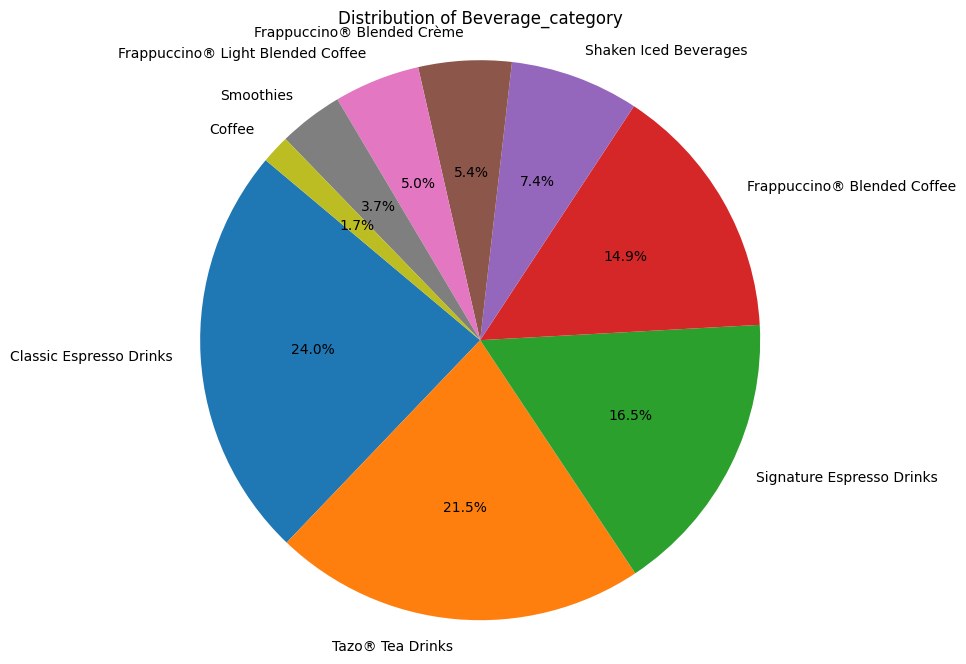

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/kaggle/input/datasets/basit026/dataset/starbucks.csv'

try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"File not found at: {file_path}")
    exit()

# --- Exploratory Data Analysis (EDA) ---
print("\n--- First 5 rows of the dataset ---")
print(df.head())

print("\n--- Dataset Info ---")
df.info()

print("\n--- Descriptive Statistics ---")
print(df.describe(include='all'))

print("\n--- Column names and data types ---")
print(df.dtypes)

# --- Pie Chart ---
# Check if 'Category' column exists
if 'Category' in df.columns:
    category_counts = df['Category'].value_counts()
    plt.figure(figsize=(10, 8))
    plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140)
    plt.title('Distribution of Starbucks Beverage Categories')
    plt.axis('equal')
    plt.show()
else:
    print("\n'Category' column not found. Looking for other suitable categorical columns for a pie chart...")
    categorical_cols = df.select_dtypes(include='object').columns
    suitable_col = None
    for col in categorical_cols:
        if df[col].nunique() < 15 and df[col].nunique() > 1:
            suitable_col = col
            break

    if suitable_col:
        print(f"Using '{suitable_col}' for pie chart.")
        counts = df[suitable_col].value_counts()
        plt.figure(figsize=(10, 8))
        plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140)
        plt.title(f'Distribution of {suitable_col}')
        plt.axis('equal')
        plt.show()
    else:
        print("No suitable categorical column found for a pie chart with less than 15 unique values.")